# Лабораторна робота № 7
## Діагностика моделей: відхилення, дисперсія, розбіжність даних і пріоритизація помилок

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали · лекції 9–10

---

### Постановка

Ви — аналітик сервісу, який читає рукописні цифри з бланків. Перші моделі навчали на
**сканах**: 20 000 чітких цифр. Тепер клієнти надсилають **фото з телефона**, і модель на них
помиляється значно частіше. У кожного варіанта — свій «телефон»: свої вади зйомки, яких вам
ніхто не опише.

Попередній аналітик залишив **виробничу модель** і пішов. Вам треба:

1. **поставити діагноз** виробничій моделі: відхилення, дисперсія чи розбіжність даних;
2. **знайти і впорядкувати за впливом** причини помилок на телефонних фото;
3. **скласти план дій** з обмеженим бюджетом і перевірити його числами.

> **Головне правило лабораторної.** Кожне твердження у звіті підкріплюється числом, яке ви
> отримали в цьому ноутбуці. «Модель перенавчилась» без двох похибок поруч — не діагноз.

| Частина | Що робите | Бали |
|---|---|---|
| 1 | відхилення і дисперсія: чотири вибірки, людський рівень, криві навчання, дії | 1,5 |
| 2 | різні розподіли: розклад похибки, аналіз 100 помилок, ліки з бюджетом, план, аналіз за частинами, критика звіту колеги | 2,0 |
| 3 | звіт і декларація про використання ШІ | 0,5 |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Стик Назарій Олегович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 17      # номер у списку групи

In [2]:
assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
print('варіант', VARIANT)

варіант 17


> Поряд із ноутбуком має лежати тека `дані/` з файлами `скани.npz`,
> `lr7_варіанти_студенту.json` і **файлом вашого варіанта** `lr7_варіант_NN.npz`
> (кожен варіант — окремий файл близько 5 МБ; завантажте свій із ВНС).

In [3]:
import importlib.util, subprocess, sys
REQUIRED = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib']
MODNAME = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [4]:
import warnings; warnings.filterwarnings('ignore')
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
import sklearn
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

DATA_DIR = 'дані'
C1, C2, C3, C4, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#c0392b', '#8a8a8a'
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)
print('scikit-learn', sklearn.__version__, '| numpy', np.__version__)

scikit-learn 1.9.1 | numpy 2.5.3


### Допоміжні функції

Їх не треба змінювати — лише розуміти, що вони роблять. Опис кожної — у рядку документації.

In [5]:
import numpy as np
from scipy import ndimage as ndi


def flat(X):
    """Зображення uint8 (n, 28, 28) → ознаки у [0, 1], форма (n, 784)."""
    return X.reshape(len(X), -1).astype(np.float32) / 255.0


def split_train_dev(n, n_dev, seed=7):
    """Індекси навчальної частини і навчально-валідаційної вибірки (training dev set)."""
    perm = np.random.default_rng(seed).permutation(n)
    return perm[n_dev:], perm[:n_dev]


def _rotate(im, deg):
    t = np.deg2rad(deg); mat = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    c = np.array(im.shape) / 2 - 0.5
    return ndi.affine_transform(im, mat, offset=c - mat @ c, order=1, mode='constant', cval=0.0)


def distort(X, seed, angle=None, blur=None, lowres=None, background=None, contrast=None, glare=None, noise=None, share=1.0):
    """Синтез «телефонних» фото з чистих цифр. Кожен параметр — пара (від, до), з якої
    для кожного зображення береться випадкове значення; None — властивість вимкнено.
    share — частка зображень, до яких застосовують задані властивості (решта лишається чистою).
      angle      — кут повороту, градуси (знак обирається випадково)
      blur       — сигма гаусового розмиття, пікселі
      lowres     — до якої роздільності стиснути і розтягнути назад, пікселі (наприклад, (9, 12))
      background — яскравість фону, 0..1;  contrast — множник яскравості штрихів, 0..1
      glare      — сила відблиску (пляма, у якій штрихи «вигорають» до кольору фону), 0..1
      noise      — стандартне відхилення шуму сенсора
    Повертає uint8 (n, 28, 28)."""
    rng = np.random.default_rng(seed); out = np.empty(X.shape, np.float32)
    yy, xx = np.mgrid[0:28, 0:28]
    u = lambda r: rng.uniform(*r)
    for k, im in enumerate(X.astype(np.float32) / 255):
        if rng.random() < share:
            if angle: im = _rotate(im, rng.choice([-1, 1]) * u(angle))
            if blur: im = ndi.gaussian_filter(im, u(blur))
            if lowres:
                L = int(round(u(lowres))); im = ndi.zoom(ndi.zoom(im, L / 28, order=1), 28 / L, order=1)[:28, :28]
            bg = u(background) if background else 0.0
            im = bg + (u(contrast) if contrast else 1.0) * im
            if glare:
                cy, cx = rng.uniform(8, 20, 2); sg = rng.uniform(3.5, 6.5)
                w = u(glare) * np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * sg * sg)); im = im * (1 - w) + w * bg
            if noise: im = im + rng.normal(0, u(noise), im.shape)
        out[k] = np.clip(im, 0, 1)
    return (out * 255).round().astype(np.uint8)


def image_stats(X):
    """Прості вимірювання кожного фото за пікселями — ними можна відбирати фото без міток."""
    rows = []
    yy, xx = np.mgrid[0:28, 0:28]
    for im in X.astype(np.float32) / 255:
        p50, p99 = np.percentile(im, [50, 99]); ink = np.clip(im - p50, 0, None); m = ink.sum() + 1e-9
        cy, cx = (ink * yy).sum() / m, (ink * xx).sum() / m
        mu20, mu02, mu11 = (ink * (xx - cx) ** 2).sum() / m, (ink * (yy - cy) ** 2).sum() / m, (ink * (xx - cx) * (yy - cy)).sum() / m
        rows.append({'контраст': p99 - p50,
                     'різкість': float(ndi.laplace(ndi.gaussian_filter(im, 0.5)).var()),
                     'нахил_осі': float(np.degrees(0.5 * np.arctan2(2 * mu11, mu02 - mu20))),
                     'шум': float((im - ndi.median_filter(im, 3)).std()),
                     'частка_чорнила': float((im > p50 + 0.5 * (p99 - p50)).mean())})
    return rows


def make_canvas(photos, seed, blobs=(1, 3), lines=0):
    """Полотна 56×56: телефонне фото цифри в довільному місці; плями-завади поза цифрою
    і (за потреби) lines горизонтальних ліній бланка. Повертає полотна (float 0..1) і справжні положення."""
    r = np.random.default_rng(seed); n = len(photos)
    X = np.clip(0.1 + r.normal(0, 0.04, (n, 56, 56)), 0, 1).astype(np.float32); pos = np.zeros((n, 2), int)
    yy, xx = np.mgrid[0:56, 0:56]
    for i in range(n):
        rr, cc = r.integers(0, 29, 2); pos[i] = (rr, cc)
        X[i, rr:rr + 28, cc:cc + 28] = np.maximum(X[i, rr:rr + 28, cc:cc + 28], photos[i].astype(np.float32) / 255)
        for _ in range(r.integers(blobs[0], blobs[1] + 1)):
            while True:
                br, bc = r.integers(2, 54, 2)
                if not (rr - 3 <= br <= rr + 30 and cc - 3 <= bc <= cc + 30):
                    break
            s, a = r.uniform(1.2, 2.2), r.uniform(0.5, 0.9)
            X[i] = np.maximum(X[i], 0.1 + a * np.exp(-((yy - br) ** 2 + (xx - bc) ** 2) / (2 * s * s)))
        for _ in range(lines):
            ly = r.integers(4, 52); X[i, ly:ly + 2, :] = np.maximum(X[i, ly:ly + 2, :], r.uniform(0.45, 0.7))
    return np.clip(X, 0, 1), pos


def locate(X, thr=0.3):
    """Компонент A (без навчання): лівий верхній кут вирізу 28×28 навколо цифри."""
    out = np.zeros((len(X), 2), int)
    for i, im in enumerate(X):
        ink = np.clip(ndi.gaussian_filter(im, 0.7) - thr, 0, None)
        s = ndi.uniform_filter(ink, size=28, mode='constant')[14:43, 14:43]
        r0, c0 = np.unravel_index(np.argmax(s), s.shape)
        w = ink[r0:r0 + 28, c0:c0 + 28].copy(); lab, n = ndi.label(w > 0)
        if n > 1:
            w[lab != 1 + np.argmax(ndi.sum(w, lab, range(1, n + 1)))] = 0
        m = w.sum() + 1e-9; cy = (w.sum(1) * np.arange(28)).sum() / m; cx = (w.sum(0) * np.arange(28)).sum() / m
        out[i] = (int(np.clip(round(r0 + cy - 14), 0, 28)), int(np.clip(round(c0 + cx - 14), 0, 28)))
    return out


def crop(X, pos):
    """Вирізи 28×28 у форматі uint8, як фото."""
    return (np.stack([X[i, p[0]:p[0] + 28, p[1]:p[1] + 28] for i, p in enumerate(pos)]) * 255).round().astype(np.uint8)


def shifted_copies(X, seed, k=2):
    """Копії зображень, зсунуті на випадкові ±k пікселів: класифікатор після локалізатора має їх витримувати."""
    r = np.random.default_rng(seed); out = np.empty_like(X)
    for i in range(len(X)):
        dy, dx = r.integers(-k, k + 1, 2); out[i] = np.roll(np.roll(X[i], dy, 0), dx, 1)
    return out

In [8]:
def err(model, X, y):
    """Похибка у відсотках (частка неправильних відповідей × 100)."""
    return round(100 * float((model.predict(X) != y).mean()), 2)


def show_grid(images, titles=None, ncol=10, size=1.05, title=None):
    """Сітка зображень; темне — чорнило."""
    n = len(images); nrow = (n + ncol - 1) // ncol
    fig, axs = plt.subplots(nrow, ncol, figsize=(size * ncol, size * nrow + (0.35 if title else 0) + 0.25 * nrow))
    for k, ax in enumerate(np.ravel(axs)):
        ax.axis('off')
        if k < n:
            ax.imshow(images[k], cmap='gray_r', vmin=0, vmax=255 if np.asarray(images[k]).max() > 1 else 1)
            if titles:
                ax.set_title(titles[k], fontsize=8)
    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.show()


_TEST_CALLS = []


def evaluate_on_test(model, name):
    """Остаточна оцінка на тестовій вибірці. Викликайте ОДИН раз — для обраної моделі."""
    _TEST_CALLS.append(name)
    if len(_TEST_CALLS) > 1:
        print('УВАГА: тестову вибірку використано вже', len(_TEST_CALLS), 'рази — це буде видно у звіті')
    return err(model, flat(TEST_X), TEST_Y)

### Дані

| Масив | Що це | Скільки |
|---|---|---|
| `SCAN_X`, `SCAN_Y` | скани: чіткі цифри | 20 000 |
| `PHONE_X`, `PHONE_Y` | телефонні фото з мітками, для навчання | 2000 |
| `POOL_X`, `POOL_Y` | телефонні фото, які можна **докупити** (частина 2; бюджет — 1000 штук) | 2000 |
| `DEV_X`, `DEV_Y` | валідаційна вибірка: телефонні фото | 1500 |
| `TEST_X`, `TEST_Y` | тестова вибірка: телефонні фото — **лише для остаточної оцінки** | 1500 |
| `HUMAN_X` | 50 фото для вимірювання людського рівня (мітки приховано) | 50 |

Валідаційна і тестова вибірки — з того розподілу, на якому сервіс має працювати:
телефонні фото (лекція 10, розділ 36).

In [6]:
S = np.load(os.path.join(DATA_DIR, 'скани.npz'))
V = np.load(os.path.join(DATA_DIR, 'lr7_варіант_%02d.npz' % VARIANT))
with open(os.path.join(DATA_DIR, 'lr7_варіанти_студенту.json'), encoding='utf-8') as f:
    INFO = json.load(f)[VARIANT - 1]
SCAN_X, SCAN_Y = S['scan_X'], S['scan_y']
PHONE_X, PHONE_Y = V['phone_train_X'], V['phone_train_y']
POOL_X, POOL_Y = V['pool_X'], V['pool_y']
DEV_X, DEV_Y = V['dev_X'], V['dev_y']
TEST_X, TEST_Y = V['test_X'], V['test_y']
HUMAN_X, HUMAN_CODE = V['human_X'], V['human_code']
for nm in ['SCAN_X', 'PHONE_X', 'POOL_X', 'DEV_X', 'TEST_X', 'HUMAN_X']:
    print('%-8s' % nm, globals()[nm].shape)
print()
print('Виробнича модель попереднього аналітика:')
print('  навчена на:', INFO['виробнича']['навчена_на'])
print('  модель:    ', INFO['виробнича']['модель'])

SCAN_X   (20000, 28, 28)
PHONE_X  (2000, 28, 28)
POOL_X   (2000, 28, 28)
DEV_X    (1500, 28, 28)
TEST_X   (1500, 28, 28)
HUMAN_X  (50, 28, 28)

Виробнича модель попереднього аналітика:
  навчена на: суміш
  модель:     make_pipeline(PCA(10, random_state=0), LogisticRegression(max_iter=300))


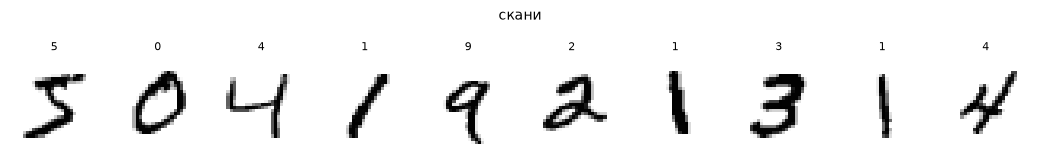

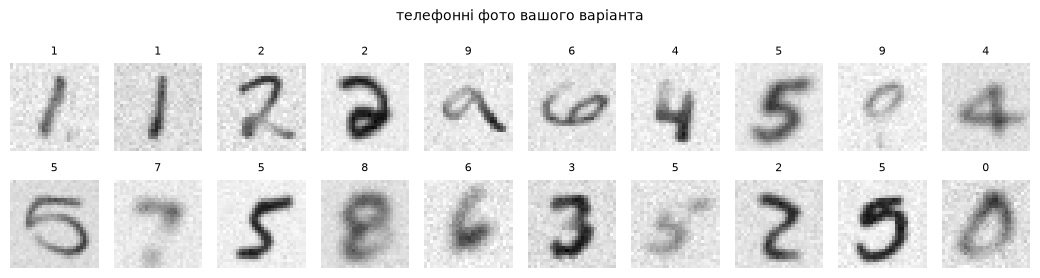

In [9]:
show_grid(SCAN_X[:10], [str(v) for v in SCAN_Y[:10]], title='скани')
show_grid(PHONE_X[:20], [str(v) for v in PHONE_Y[:20]], title='телефонні фото вашого варіанта')

---
# Частина 1. Відхилення і дисперсія (1,5 бала)
---
## 1. Чотири вибірки

Зазвичай є три: навчальна, валідаційна, тестова. Але в нас модель вчиться на одних даних (переважно сканах), а працювати має на інших (телефонних фото). Тому з'являється четверта:

| вибірка | звідки | навіщо |
| :--- | :--- | :--- |
| **навчальна** ( `X_tr` ) | джерело, на якому вчиться модель | на ній модель вчиться |
| **навчально-валідаційна** ( `X_td` ) | **те саме джерело**, але модель її не бачила | перевірити, чи модель не зазубрила дані |
| **валідаційна** ( `X_dev` ) | телефонні фото | як модель працює там, де має працювати |
| **тестова** ( `TEST_X` ) | телефонні фото | одна фінальна оцінка в кінці |

Щоб розрізнити дисперсію і розбіжність даних, потрібна **навчально-валідаційна вибірка**
(training dev set): приклади з **того самого розподілу, на якому вчилася модель**, але не
показані їй під час навчання (лекція 10, розділ 40).

Виробнича модель навчалась на джерелі, назва якого надрукована вище. Оберіть те саме
джерело і відкладіть із нього навчально-валідаційну вибірку:

| джерело | що це | скільки відкласти |
|---|---|---|
| `'скани'` | лише 20 000 сканів | 2000 |
| `'телефон'` | лише 2000 телефонних фото | 400 |
| `'суміш'` | 20 000 сканів + 2000 фото | 2000 |

### Завдання 1.1

In [10]:
# ----- ВАШІ ВІДПОВІДІ -----
TRAIN_SOURCE = 'суміш'     # 'скани' / 'телефон' / 'суміш'
# чому навчально-валідаційну вибірку треба брати саме звідси, а не з телефонних фото:
WHY_TRAIN_DEV = ('Виробнича модель навчалась на суміші (20 000 сканів + 2000 телефонних фото), тому '
                 'навчально-валідаційну вибірку відкладаємо з того самого розподілу - з суміші. '
                 'Тоді різниця E_навч-вал - E_навч показує лише дисперсію (наскільки модель погіршується '
                 'на нових прикладах того самого розподілу), а різниця E_вал - E_навч-вал - лише розбіжність '
                 'даних (суміш vs телефонні фото). Якби навчально-валідаційну вибірку взяли з телефонних фото, '
                 'у першу різницю потрапила б і розбіжність розподілів, і дисперсію не можна було б відділити '
                 'від розбіжності даних.')
# ----- КІНЕЦЬ -----

In [11]:
SOURCES = {'скани': (SCAN_X, SCAN_Y), 'телефон': (PHONE_X, PHONE_Y),
           'суміш': (np.concatenate([SCAN_X, PHONE_X]), np.concatenate([SCAN_Y, PHONE_Y]))}
N_TRAIN_DEV = {'скани': 2000, 'телефон': 400, 'суміш': 2000}
assert TRAIN_SOURCE in SOURCES, 'оберіть одне з трьох джерел'
assert WHY_TRAIN_DEV, 'поясніть вибір'
SRC_X, SRC_Y = SOURCES[TRAIN_SOURCE]
idx_tr, idx_td = split_train_dev(len(SRC_Y), N_TRAIN_DEV[TRAIN_SOURCE])
X_tr, y_tr = flat(SRC_X[idx_tr]), SRC_Y[idx_tr]
X_td, y_td = flat(SRC_X[idx_td]), SRC_Y[idx_td]
X_dev, y_dev = flat(DEV_X), DEV_Y
print(f'навчальна: {len(y_tr)} | навчально-валідаційна: {len(y_td)} | валідаційна: {len(y_dev)} | тестова: {len(TEST_Y)} (не чіпаємо)')

навчальна: 20000 | навчально-валідаційна: 2000 | валідаційна: 1500 | тестова: 1500 (не чіпаємо)


## 2. Людський рівень

Оптимальну похибку ми не знаємо, тож оцінюємо її **людським рівнем** — найкращим, якого
досягає людина на тих самих фото (лекція 10, розділи 33–34). Подивіться на 50 фото свого
варіанта і впишіть цифри підряд — 50 символів, пробіли не важливі. Не збільшуйте зображення
більше, ніж його бачить модель, і не підглядайте в мітки.

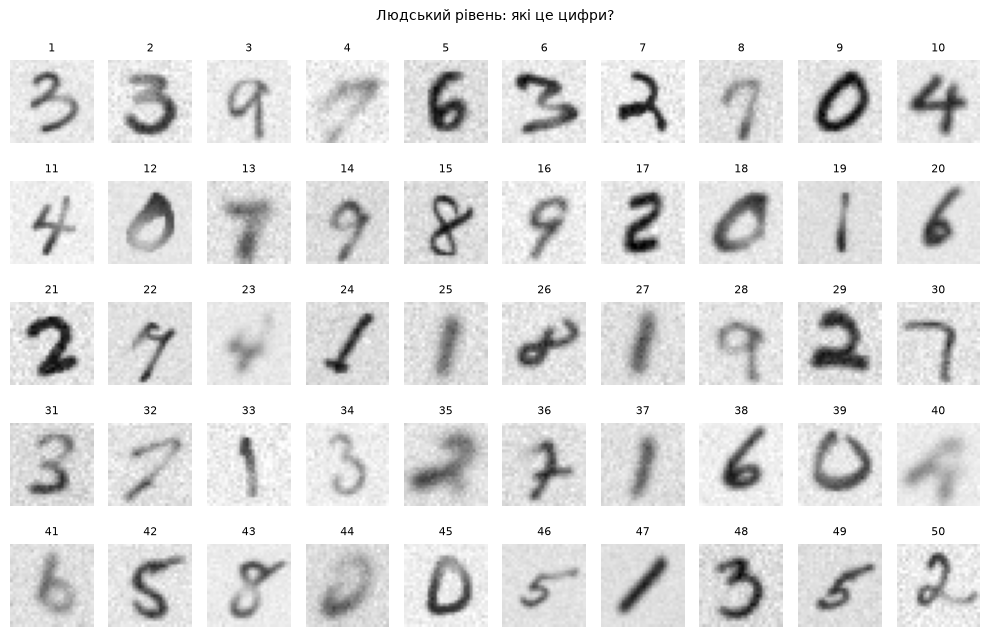

In [12]:
show_grid(HUMAN_X, [str(k + 1) for k in range(50)], size=1.0, title='Людський рівень: які це цифри?')

### Завдання 2.1

In [14]:
# ----- ВАШІ ВІДПОВІДІ -----
HUMAN_ANSWERS = '3397632704 4079892016 2441181927 3213271604 6580051352'
# ----- КІНЕЦЬ -----

In [15]:
ans = [int(c) for c in HUMAN_ANSWERS if c.isdigit()]
assert len(ans) == 50, f'потрібно 50 цифр, а введено {len(ans)}'
truth = (HUMAN_CODE - 7 * np.arange(50)) % 10
HUMAN_ERR = round(100 * float(np.mean(np.array(ans) != truth)), 1)
print('ваша похибка на 50 фото:', HUMAN_ERR, '%')
print('номери фото, де ви помилились:', [k + 1 for k in range(50) if ans[k] != truth[k]])

ваша похибка на 50 фото: 4.0 %
номери фото, де ви помилились: [22, 32]


> **Одна помилка на 50 фото — це 2 %, і довірчий інтервал такої оцінки широкий.**
> Як людський рівень беріть найкращий результат, якого досягла людина на цих фото: якщо
> одногрупник із тим самим варіантом має менше помилок — використайте його число і
> зазначте це у звіті.

## 3. Діагноз виробничої моделі

Відтворюємо виробничу модель і рахуємо похибки на трьох вибірках. Розклад (лекція 10, розділ 41):

$$\underbrace{E_{\text{навч}} - E_{\text{людина}}}_{\text{усувне відхилення}},\qquad
\underbrace{E_{\text{навч-вал}} - E_{\text{навч}}}_{\text{дисперсія}},\qquad
\underbrace{E_{\text{вал}} - E_{\text{навч-вал}}}_{\text{розбіжність даних}}$$

In [16]:
PRODUCTION = eval(INFO['виробнича']['модель'])        # модель саме в тому вигляді, як її записав попередній аналітик
t0 = time.time()
prod = PRODUCTION.fit(X_tr, y_tr)
E_PROD = {'навч': err(prod, X_tr, y_tr), 'навч_вал': err(prod, X_td, y_td), 'вал': err(prod, X_dev, y_dev)}
print(f'навчено за {time.time() - t0:.0f} с')
print('похибки виробничої моделі, %:', E_PROD)
DECOMP_PROD = {'усувне відхилення': round(E_PROD['навч'] - HUMAN_ERR, 2),
               'дисперсія': round(E_PROD['навч_вал'] - E_PROD['навч'], 2),
               'розбіжність даних': round(E_PROD['вал'] - E_PROD['навч_вал'], 2)}
pd.Series(DECOMP_PROD, name='п. п.').to_frame()

навчено за 1 с
похибки виробничої моделі, %: {'навч': 21.02, 'навч_вал': 22.35, 'вал': 31.67}


,п. п.
усувне відхилення,17.02
дисперсія,1.33
розбіжність даних,9.32


### Завдання 3.1

Поставте діагноз. Якщо дві складові близькі, назвіть головну і поясніть, чому друга —
другорядна.

In [17]:
# ----- ВАШІ ВІДПОВІДІ -----
DIAGNOSIS = 'відхилення'        # 'відхилення' / 'дисперсія' / 'розбіжність'
# доказ числами (дві похибки поруч і різниця між ними):
DIAGNOSIS_WHY = ('Головна проблема - високе усувне відхилення: E_навч = 21.02 % при людському рівні 4.0 %, '
                 'різниця 17.02 п. п. Модель помиляється у кожному п\'ятому прикладі навіть на даних, на яких '
                 'навчалась, бо PCA(10) + логістична регресія занадто проста (784 пікселі стиснуто до 10 ознак). '
                 'Дисперсія мала: E_навч-вал - E_навч = 22.35 - 21.02 = 1.33 п. п., тобто модель не перенавчилась. '
                 'Розбіжність даних E_вал - E_навч-вал = 31.67 - 22.35 = 9.32 п. п. теж помітна, але вона другорядна: '
                 'майже вдвічі менша за відхилення, і її є сенс лікувати лише після того, як модель стане достатньо '
                 'складною, щоб добре навчатися (спочатку усуваємо відхилення, потім розбіжність).')
# ----- КІНЕЦЬ -----

In [18]:
assert DIAGNOSIS in ('відхилення', 'дисперсія', 'розбіжність') and DIAGNOSIS_WHY, 'заповніть діагноз і доказ'
print('діагноз:', DIAGNOSIS)

діагноз: відхилення


## 4. Крива навчання

Крива навчання показує, чи допоможуть **ще дані того самого розподілу** (лекція 9, розділи 28–30).
Навчаємо виробничу модель на 10, 25, 50 і 100 % навчальної частини і дивимось на похибку на
навчальній і навчально-валідаційній вибірках; пунктиром — валідаційна похибка повної моделі
і ваш людський рівень. Це триває 1–3 хвилини.

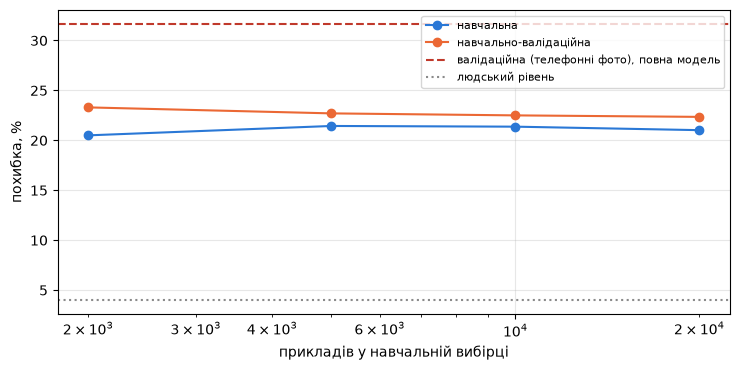

,n,навч,навч_вал
0,2000,20.50,23.30
1,5000,21.44,22.70
2,10000,21.37,22.50
3,20000,21.02,22.35


In [19]:
curve = []
for frac in [0.1, 0.25, 0.5, 1.0]:
    n = max(50, int(len(y_tr) * frac))
    m = eval(INFO['виробнича']['модель']).fit(X_tr[:n], y_tr[:n])
    curve.append({'n': n, 'навч': err(m, X_tr[:n], y_tr[:n]), 'навч_вал': err(m, X_td, y_td)})
CURVE = pd.DataFrame(curve)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(CURVE['n'], CURVE['навч'], 'o-', color=C1, label='навчальна')
ax.plot(CURVE['n'], CURVE['навч_вал'], 'o-', color=C2, label='навчально-валідаційна')
ax.axhline(E_PROD['вал'], ls='--', color=C4, label='валідаційна (телефонні фото), повна модель')
ax.axhline(HUMAN_ERR, ls=':', color=GREY, label='людський рівень')
ax.set_xscale('log'); ax.set_xlabel('прикладів у навчальній вибірці'); ax.set_ylabel('похибка, %')
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
CURVE

### Завдання 4.1

In [20]:
# ----- ВАШІ ВІДПОВІДІ -----
MORE_SAME_DATA_HELPS = False   # True / False: чи зменшать валідаційну похибку ще дані ТОГО САМОГО джерела?
# що на графіку це показує (форма двох кривих, розрив між ними, де валідаційна лінія):
CURVE_WHY = ('Обидві криві майже пласкі: при збільшенні навчальної вибірки в 10 разів (з 2000 до 20000) '
             'навчально-валідаційна похибка впала лише з 23.30 % до 22.35 % (на 0.95 п. п.), а з 10000 до 20000 - '
             'лише на 0.15 п. п. Розрив між кривими малий (1.33 п. п. на 20000) і вже не зменшується, тобто дисперсії, '
             'яку лікують додаткові дані, немає. Обидві криві вийшли на плато близько 21-22 %, далеко над людським '
             'рівнем 4 % - це ознака високого відхилення: модель PCA(10) + логістична регресія занадто проста. '
             'Валідаційна лінія (31.67 %) ще вище, і дані того самого джерела (суміші) не зменшать і розбіжність даних. '
             'Тому потрібна складніша модель, а не більше тих самих даних.')
# ----- КІНЕЦЬ -----

In [21]:
assert MORE_SAME_DATA_HELPS in (True, False) and CURVE_WHY, 'заповніть висновок за кривою'

## 5. Дії: що допомагає, а що — ні

Таблиці лекції 9 (розділи 25 і 27) кажуть, які дії зменшують відхилення, а які — дисперсію;
лекція 10 (розділи 37–43) — що робити з розбіжністю. Перевірте це на своїй моделі:

* **дві дії**, які, за вашим діагнозом, мають допомогти;
* **одну контрольну дію**, спрямовану на **іншу** проблему, — вона допомогти не повинна.

Кожна дія — це модель і навчальні дані. Похибки рахуються на тих самих навчально-валідаційній
і валідаційній вибірках, що й у пункті 3. Готові «цеглинки»:
`X_tr, y_tr` — навчальна частина вашого джерела; `flat(SCAN_X), SCAN_Y` — усі скани;
`flat(PHONE_X), PHONE_Y` — усі телефонні фото (увага: частина з них — у навчально-валідаційній
вибірці, якщо джерело `'телефон'` чи `'суміш'`; використовуйте `X_tr` і додавайте до нього
лише те, чого в ній немає); `SRC_X[idx_tr]` — ті самі навчальні приклади як зображення, з яких
`shifted_copies(SRC_X[idx_tr], seed, k)` робить копії, зсунуті на ±k пікселів (аугментація);
`distort(...)` — синтез «телефонних» фото (опис — у розділі 8).

Приклад запису:

```python
('більша модель: MLP(256)', 'відхилення',
 MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0), X_tr, y_tr)
```

Одна дія навчається від кількох секунд до хвилини.

In [22]:
# ----- ВАШІ ВІДПОВІДІ -----
ACTIONS = [
    # (назва дії, на яку проблему спрямована, модель, навчальні X, навчальні y)
    ('більше ознак: PCA(100) + LogReg', 'відхилення',
     make_pipeline(PCA(100, random_state=0), LogisticRegression(max_iter=300)), X_tr, y_tr),
    ('більша модель: MLP(256) без PCA', 'відхилення',
     MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0), X_tr, y_tr),
    ('контроль: сильніша регуляризація C=0.01', 'дисперсія',
     make_pipeline(PCA(10, random_state=0), LogisticRegression(C=0.01, max_iter=300)), X_tr, y_tr),
]
# ----- КІНЕЦЬ -----

In [23]:
assert len(ACTIONS) >= 3, 'потрібно щонайменше три дії: дві за діагнозом і одна контрольна'
rows = [{'дія': 'виробнича модель (до змін)', 'на що спрямована': '—', **E_PROD}]
for name, target, model, Xa, ya in ACTIONS:
    t0 = time.time(); model.fit(Xa, ya)
    rows.append({'дія': name, 'на що спрямована': target, 'навч': err(model, Xa, ya),
                 'навч_вал': err(model, X_td, y_td), 'вал': err(model, X_dev, y_dev)})
    print(f'{name}: {time.time() - t0:.0f} с')
ACT_TABLE = pd.DataFrame(rows)
ACT_TABLE['Δ дисперсії, п. п.'] = (ACT_TABLE['навч_вал'] - ACT_TABLE['навч']) - (E_PROD['навч_вал'] - E_PROD['навч'])
ACT_TABLE['Δ відхилення, п. п.'] = ACT_TABLE['навч'] - E_PROD['навч']
ACT_TABLE['Δ валідаційної, п. п.'] = ACT_TABLE['вал'] - E_PROD['вал']
ACT_TABLE.round(2)

більше ознак: PCA(100) + LogReg: 2 с
більша модель: MLP(256) без PCA: 14 с
контроль: сильніша регуляризація C=0.01: 1 с


,дія,на що спрямована,навч,навч_вал,вал,"Δ дисперсії, п. п.","Δ відхилення, п. п.","Δ валідаційної, п. п."
0,виробнича модель (до змін),—,21.02,22.35,31.67,0.00,0.00,0.00
1,більше ознак: PCA(100) + LogReg,відхилення,8.06,9.20,16.13,-0.19,-12.96,-15.54
2,більша модель: MLP(256) без PCA,відхилення,0.00,3.30,9.00,1.97,-21.02,-22.67
3,контроль: сильніша регуляризація C=0.01,дисперсія,21.45,22.75,30.27,-0.03,0.43,-1.40


### Завдання 5.1

In [26]:
# ----- ВАШІ ВІДПОВІДІ -----
# що допомогло, що ні і чому — числами з таблиці; чи справдився прогноз для контрольної дії:
ACTIONS_CONCLUSION = ('Обидві дії проти відхилення допомогли, що підтверджує діагноз. '
                      'PCA(100) + LogReg: навчальна похибка 21.02 -> 8.06 % (Δ відхилення -12.96 п. п.), '
                      'валідаційна 31.67 -> 16.13 % (-15.54 п. п.), дисперсія майже не змінилась (-0.19 п. п.). '
                      'MLP(256) без PCA дала найбільший ефект: навчальна 0.00 % (Δ відхилення -21.02 п. п., '
                      'відхилення усунуто повністю), валідаційна 9.00 % (-22.67 п. п.); дисперсія трохи зросла (+1.97 п. п., '
                      'розрив 3.30 п. п.), але це значно менше за виграш. Після неї головною складовою стала розбіжність даних: '
                      '9.00 - 3.30 = 5.70 п. п. '
                      'Контрольна дія (сильніша регуляризація C=0.01, спрямована на дисперсію) не допомогла, як і прогнозувалось: '
                      'дисперсія не змінилась (-0.03 п. п.), бо її майже не було, а відхилення трохи зросло (+0.43 п. п.), '
                      'бо регуляризація ще більше обмежила і так занадто просту модель. Валідаційна похибка зменшилась лише '
                      'на 1.40 п. п. (до 30.27 %) - у 16 разів менше, ніж у MLP, і модель лишилась на рівні ~30 %, '
                      'тобто головну проблему (відхилення) ця дія не вирішує.')
# ----- КІНЕЦЬ -----

In [27]:
assert ACTIONS_CONCLUSION, 'сформулюйте висновок'

---
# Частина 2. Різні розподіли і пріоритизація помилок (2,0 бала)
---
## 6. Модель B і розклад її похибки

Далі працюємо з моделлю, яку радить лекція 10 (розділ 37): велика мережа на **суміші** сканів і
телефонних фото. Навчально-валідаційна вибірка — 2000 прикладів суміші.

навчено за 15 с; похибки моделі B, %: {'навч': 0.0, 'навч_вал': 3.3, 'вал': 9.0}


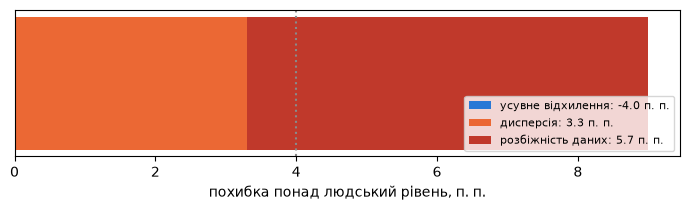

In [28]:
MIX_X, MIX_Y = SOURCES['суміш']
mix_tr, mix_td = split_train_dev(len(MIX_Y), 2000)
XB_tr, yB_tr = flat(MIX_X[mix_tr]), MIX_Y[mix_tr]
XB_td, yB_td = flat(MIX_X[mix_td]), MIX_Y[mix_td]


def model_b():
    return MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0)


t0 = time.time()
B = model_b().fit(XB_tr, yB_tr)
pred_B = B.predict(X_dev)
E_B = {'навч': err(B, XB_tr, yB_tr), 'навч_вал': err(B, XB_td, yB_td), 'вал': err(B, X_dev, y_dev)}
print(f'навчено за {time.time() - t0:.0f} с; похибки моделі B, %:', E_B)
DECOMP_B = {'усувне відхилення': round(E_B['навч'] - HUMAN_ERR, 2), 'дисперсія': round(E_B['навч_вал'] - E_B['навч'], 2),
            'розбіжність даних': round(E_B['вал'] - E_B['навч_вал'], 2)}
fig, ax = plt.subplots(figsize=(7, 2.2))
left = 0
for (k, v), c in zip(DECOMP_B.items(), [C1, C2, C4]):
    ax.barh(0, max(v, 0), left=left, color=c, label=f'{k}: {v} п. п.'); left += max(v, 0)
ax.axvline(HUMAN_ERR, color=GREY, ls=':'); ax.set_yticks([]); ax.set_xlabel('похибка понад людський рівень, п. п.')
ax.legend(fontsize=8, loc='lower right'); plt.tight_layout(); plt.show()

### Завдання 6.1

In [30]:
# ----- ВАШІ ВІДПОВІДІ -----
DIAGNOSIS_B = 'розбіжність'      # 'відхилення' / 'дисперсія' / 'розбіжність'
# чому саме це і чому більше сканів тут не допоможе (або допоможе):
DIAGNOSIS_B_WHY = ('Похибки моделі B: навчальна 0.0 %, навчально-валідаційна 3.3 %, валідаційна 9.0 %. '
                   'Усувне відхилення від\'ємне (0.0 - 4.0 = -4.0 п. п.): на навчальній суміші, яка на ~91 % складається '
                   'з чистих сканів, модель уже краща за людський рівень на телефонних фото, тож відхилення усунуто. '
                   'Дисперсія 3.3 - 0.0 = 3.3 п. п., розбіжність даних 9.0 - 3.3 = 5.7 п. п. - найбільша складова: '
                   'на телефонних фото модель помиляється майже втричі частіше, ніж на нових прикладах суміші. '
                   'Більше сканів не допоможе: вони з того самого розподілу, що й навчальні дані, тому можуть лише трохи '
                   'зменшити дисперсію (3.3 п. п.), але не навчать модель читати розмиті, шумні та засвічені фото. '
                   'Розбіжність зменшують лише дані, схожі на телефонні фото: справжні фото з пулу або синтетичні фото.')
# ----- КІНЕЦЬ -----

In [31]:
assert DIAGNOSIS_B in ('відхилення', 'дисперсія', 'розбіжність') and DIAGNOSIS_B_WHY

## 7. Аналіз 100 помилок

Метод лекції 9 (розділи 14–19) і лекції 10 (розділ 42): переглянути помилки **очима**,
позначити, що з кожним фото не так, і порахувати, скільки дасть усунення кожної причини.

Нижче — перші 100 помилок моделі B на валідаційній вибірці (у порядку номерів фото). Над
кожним фото: порядковий номер помилки, **мітка → прогноз моделі**.

**Словник категорій** (можна кілька через `+`):

| категорія | як виглядає |
|---|---|
| `нахил` | цифра помітно повернута |
| `розмиття` | штрихи розмиті, краї нечіткі |
| `низька роздільність` | «сходинки», цифра наче з кількох великих пікселів |
| `тьмяність` | сірий фон, блідий слабкий штрих |
| `відблиск` | частина штриха «вигоріла» до кольору фону |
| `шум` | зерно, крапки по всьому фото |
| `хибна мітка:N` | модель, схоже, права, а мітка хибна; N — правильна, на вашу думку, цифра |
| `нерозбірливо` | людина теж не впевнена |
| `інше` | нічого з переліченого |

Приклад: `'нахил+шум'`, `'хибна мітка:4'`, `'інше'`.

помилок моделі B на валідаційній вибірці: 135 | переглядаємо: 100


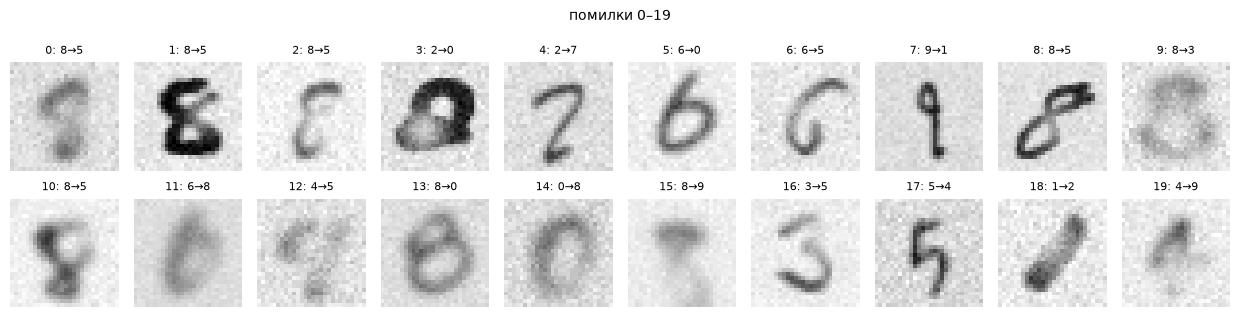

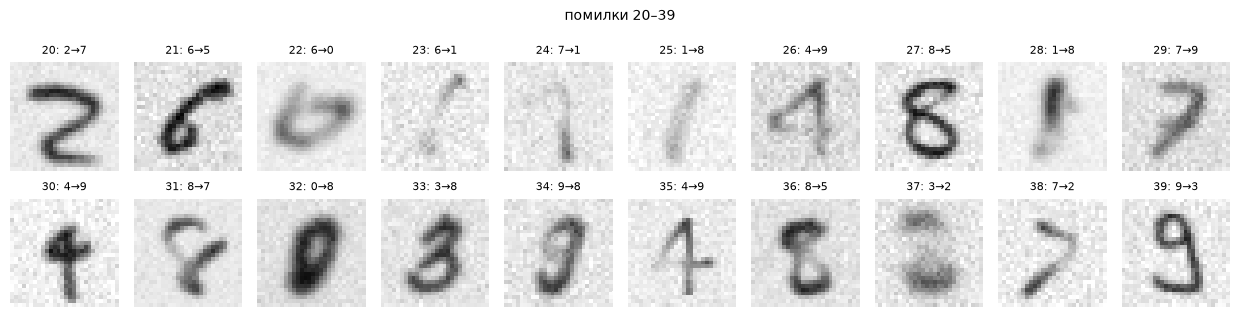

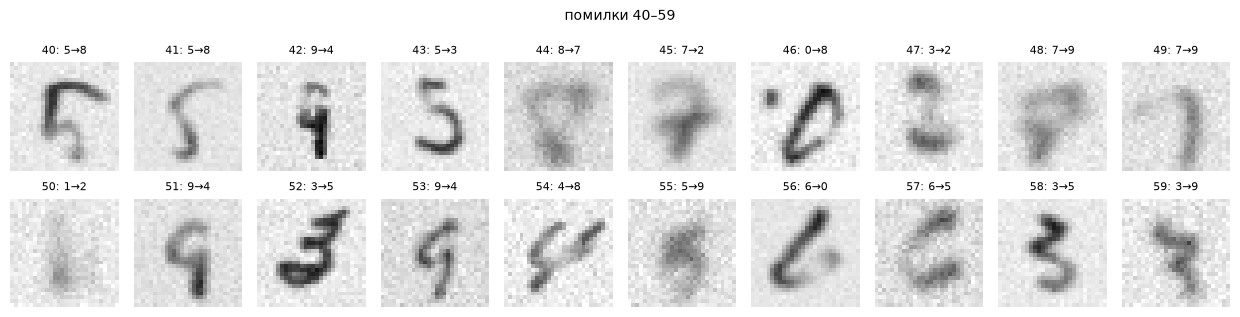

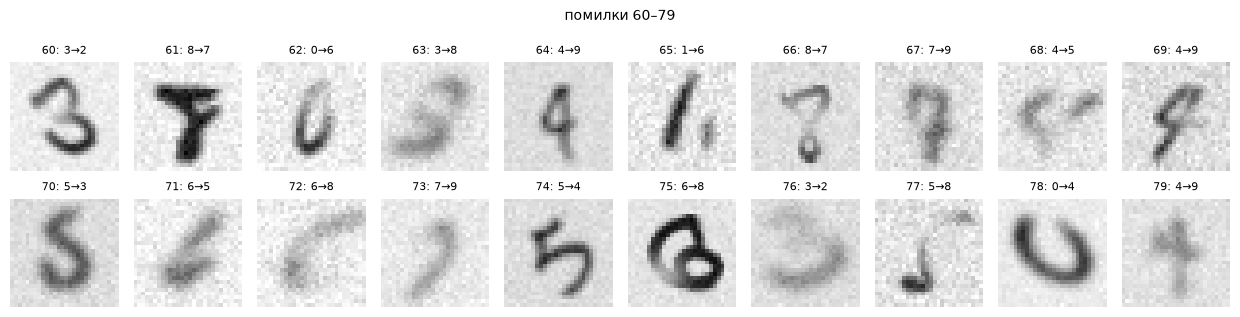

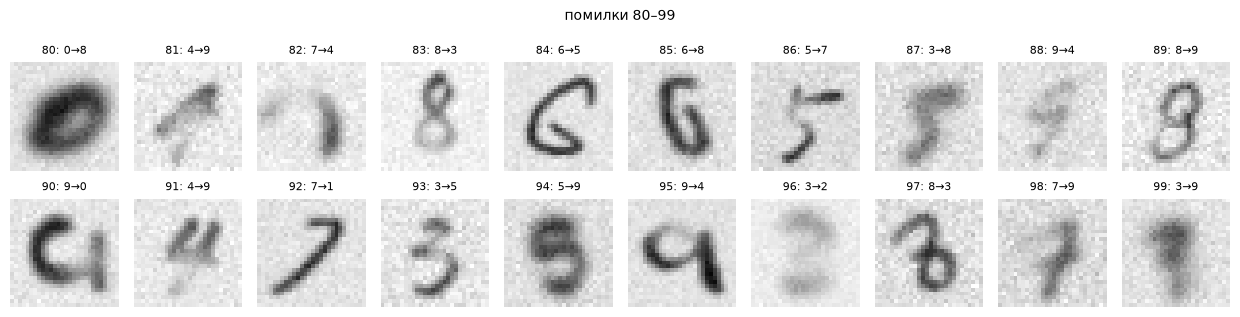

In [32]:
ERR_IDX = np.where(pred_B != DEV_Y)[0][:100]
print('помилок моделі B на валідаційній вибірці:', int((pred_B != DEV_Y).sum()), '| переглядаємо:', len(ERR_IDX))
for page in range(0, len(ERR_IDX), 20):
    ids = ERR_IDX[page:page + 20]
    show_grid(DEV_X[ids], [f'{page + k}: {DEV_Y[i]}→{pred_B[i]}' for k, i in enumerate(ids)], size=1.25,
              title=f'помилки {page}–{page + len(ids) - 1}')

### Завдання 7.1

Заповніть по одному рядку на помилку, у тому самому порядку (якщо помилок менше 100 — лише стільки
рядків, скільки помилок; зайві залиште порожніми). Це найдовша, але й
найважливіша частина роботи: на ній стоїть увесь план.

In [36]:
# ----- ВАШІ ВІДПОВІДІ -----
TAGS = [
    'розмиття+відблиск', 'розмиття', 'відблиск', 'розмиття', 'інше', 'інше', 'інше', 'інше', 'інше', 'відблиск',   # 0–9
    'розмиття', 'розмиття+відблиск', 'відблиск', 'розмиття', 'розмиття', 'відблиск', 'інше', 'інше', 'розмиття', 'відблиск',   # 10–19
    'інше', 'інше', 'розмиття', 'відблиск', 'відблиск', 'відблиск', 'розмиття', 'інше', 'розмиття', 'розмиття',   # 20–29
    'інше', 'відблиск', 'розмиття', 'розмиття', 'розмиття', 'інше', 'розмиття', 'розмиття+нерозбірливо', 'інше', 'інше',   # 30–39
    'розмиття', 'відблиск', 'інше', 'інше', 'розмиття+нерозбірливо', 'розмиття', 'інше', 'розмиття+відблиск', 'розмиття+нерозбірливо', 'відблиск',   # 40–49
    'відблиск', 'розмиття', 'інше', 'розмиття', 'інше', 'розмиття+нерозбірливо', 'відблиск', 'розмиття', 'розмиття', 'розмиття+нерозбірливо',   # 50–59
    'інше', 'розмиття', 'інше', 'розмиття+відблиск', 'розмиття', 'інше', 'відблиск', 'розмиття', 'відблиск', 'розмиття',   # 60–69
    'розмиття', 'розмиття+відблиск', 'розмиття+відблиск', 'відблиск', 'інше', 'інше', 'відблиск', 'відблиск', 'відблиск', 'розмиття+відблиск',   # 70–79
    'розмиття', 'відблиск', 'відблиск', 'відблиск', 'інше', 'інше', 'інше', 'розмиття', 'відблиск', 'інше',   # 80–89
    'розмиття', 'відблиск', 'інше', 'відблиск', 'розмиття', 'інше', 'розмиття+відблиск', 'інше', 'розмиття', 'розмиття+нерозбірливо',   # 90–99
]
# ----- КІНЕЦЬ -----

In [37]:
CATS = ['нахил', 'розмиття', 'низька роздільність', 'тьмяність', 'відблиск', 'шум', 'хибна мітка', 'нерозбірливо', 'інше']
assert len(TAGS) >= len(ERR_IDX), f'потрібно {len(ERR_IDX)} рядків, а у списку {len(TAGS)}'
TAGS = TAGS[:len(ERR_IDX)]
parsed, relabel = [], {}
for k, t in enumerate(TAGS):
    assert t.strip(), f'рядок {k} порожній'
    cs = []
    for part in t.split('+'):
        part = part.strip()
        if part.startswith('хибна мітка'):
            cs.append('хибна мітка')
            if ':' in part:
                relabel[int(ERR_IDX[k])] = int(part.split(':')[1])
        else:
            assert part in CATS, f'рядок {k}: невідома категорія «{part}»'
            cs.append(part)
    parsed.append(set(cs))
n = len(parsed)
ERR_TABLE = pd.DataFrame([{'категорія': c, 'помилок': sum(c in p for p in parsed)} for c in CATS])
ERR_TABLE['частка помилок, %'] = (100 * ERR_TABLE['помилок'] / n).round(1)
ERR_TABLE['стеля: на скільки п. п. впаде похибка'] = (E_B['вал'] * ERR_TABLE['помилок'] / n).round(2)
ERR_TABLE = ERR_TABLE.sort_values('помилок', ascending=False).reset_index(drop=True)
print('похибка моделі B на валідаційній:', E_B['вал'], '%; категорії можуть перетинатись, тож сума часток > 100 %')
ERR_TABLE

похибка моделі B на валідаційній: 9.0 %; категорії можуть перетинатись, тож сума часток > 100 %


,категорія,помилок,"частка помилок, %",стеля: на скільки п. п. впаде похибка
0,розмиття,44,44.0,3.96
1,відблиск,33,33.0,2.97
2,інше,31,31.0,2.79
3,нерозбірливо,6,6.0,0.54
4,нахил,0,0.0,0.00
5,тьмяність,0,0.0,0.00
6,низька роздільність,0,0.0,0.00
7,хибна мітка,0,0.0,0.00
8,шум,0,0.0,0.00


**Хибні мітки.** Якщо ви позначили фото як `хибна мітка:N`, нижче похибка моделі B за
**виправленими** мітками валідаційної вибірки. Яка частина похибки — не провина моделі?

In [35]:
DEV_Y_FIXED = DEV_Y.copy()
for i, lab in relabel.items():
    DEV_Y_FIXED[i] = lab
E_B_FIXED = round(100 * float((pred_B != DEV_Y_FIXED).mean()), 2)
print(f'виправлено міток: {len(relabel)}; похибка B: {E_B["вал"]} % → {E_B_FIXED} % за виправленими мітками')

виправлено міток: 0; похибка B: 9.0 % → 9.0 % за виправленими мітками


### Завдання 7.2

Упорядкуйте **до трьох** напрямів роботи за впливом — від найбільшої стелі до меншої. Для хибних
міток рішення інше: їх не «лікують» моделлю, а перевіряють і виправляють розмітку
(лекція 9, розділ 16).

In [38]:
# ----- ВАШІ ВІДПОВІДІ -----
PRIORITY = ['розмиття', 'відблиск']          # до трьох категорій зі словника, від найважливішої
# чому саме такий порядок і що ви зробите з кожною категорією:
PRIORITY_WHY = ('Порядок - за стелею (максимальним зменшенням похибки, якщо категорію усунути повністю). '
                '1) Розмиття: 44 зі 100 помилок, стеля 9.0 * 0.44 = 3.96 п. п. Дії: докупити з пулу фото з малою '
                'різкістю (дисперсія лапласіана) і синтезувати фото зі сканів із розмиттям blur, заданим діапазоном. '
                '2) Відблиск: 33 помилки, стеля 2.97 п. п. Дії: відбирати з пулу фото з малою часткою чорнила та '
                'низькою впевненістю моделі B, у синтезі додати glare діапазоном. 8 фото мають обидві вади, тому '
                'спільна стеля двох категорій - 69 помилок, тобто 6.21 п. п. (з 9.0 % до ~2.8 %). '
                'Категорію «інше» (31 помилка, 2.79 п. п.) у пріоритет не беру: це незвичний почерк на нормальних фото, '
                'для нього немає цілеспрямованих ліків. «Нерозбірливо» (6 помилок, 0.54 п. п.) не лікується моделлю, бо '
                'і людина не впевнена. Хибних міток не знайдено (0), тож похибка за виправленими мітками не змінилась '
                '(9.0 %), і перевіряти розмітку валідаційної вибірки зараз не потрібно.')
# ----- КІНЕЦЬ -----

In [39]:
assert 1 <= len(PRIORITY) <= 3 and all(p in CATS for p in PRIORITY) and PRIORITY_WHY

## 8. Ліки від розбіжності: бюджет — 1000 фото

Варіанти з лекції 10 (розділи 42–43):

1. **докупити** 1000 справжніх телефонних фото з пулу — випадкових;
2. **докупити** 1000 фото, **відібраних без міток**: за вимірюваннями пікселів
   (`image_stats`) або за невпевненістю моделі B (`B.predict_proba`);
3. **синтезувати** 20 000 «телефонних» фото зі сканів функцією `distort` — бюджету не потребує.

Купити можна лише **одну** тисячу. Кожен варіант навчається 30–60 с.

In [40]:
def train_with(extra_X, extra_y):
    """Модель B, навчена на суміші плюс додаткових даних; повертає модель і валідаційну похибку."""
    m = model_b().fit(np.concatenate([XB_tr, flat(extra_X)]), np.concatenate([yB_tr, extra_y]))
    return m, err(m, X_dev, y_dev)


FIX = [{'ліки': 'база: модель B', 'вал': E_B['вал']}]
rand_idx = np.random.default_rng(11).permutation(len(POOL_Y))[:1000]
m_rand, e = train_with(POOL_X[rand_idx], POOL_Y[rand_idx])
FIX.append({'ліки': '+1000 випадкових фото з пулу', 'вал': e}); pd.DataFrame(FIX)

,ліки,вал
0,база: модель B,9.00
1,+1000 випадкових фото з пулу,8.53


### Завдання 8.1. Цілеспрямована покупка

Відберіть 1000 фото з пулу, **не дивлячись на мітки** `POOL_Y`, — так, щоб серед них було
якомога більше фото з категорії-пріоритету. Вимірювання кожного фото пулу вже пораховано:

In [41]:
POOL_STATS = pd.DataFrame(image_stats(POOL_X))
POOL_STATS['впевненість_B'] = B.predict_proba(flat(POOL_X)).max(1)
POOL_STATS.describe().round(3)

,контраст,різкість,нахил_осі,шум,частка_чорнила,впевненість_B
count,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000
mean,0.571,0.014,-7.273,0.040,0.126,0.929
std,0.150,0.008,28.103,0.009,0.041,0.137
min,0.149,0.002,-89.994,0.019,0.032,0.272
25%,0.463,0.008,-25.978,0.033,0.096,0.937
50%,0.581,0.012,-9.114,0.040,0.122,0.995
75%,0.687,0.017,8.095,0.046,0.153,1.000
max,0.886,0.070,89.207,0.073,0.302,1.000


Підказки: `контраст` — різниця між штрихом і фоном; `різкість` — дисперсія лапласіана
(розмиті й низької роздільності фото мають малу); `шум` — залишок після медіанного фільтра;
`частка_чорнила` — частка пікселів, яскравіших за середину між фоном і штрихом;
`нахил_осі` — кут головної осі цифри (слабка ознака: цифри й самі бувають нахилені);
`впевненість_B` — найбільша ймовірність, яку дає модель B (мала — модель сумнівається).

```python
SELECT = POOL_STATS.sort_values('контраст').index[:1000].to_numpy()   # приклад: найменш контрастні
```

In [42]:
# ----- ВАШІ ВІДПОВІДІ -----
score = POOL_STATS['різкість'].rank() + POOL_STATS['впевненість_B'].rank()
SELECT = score.sort_values().index[:1000].to_numpy()          # масив із 1000 номерів фото пулу
SELECT_WHY = ('Пріоритети - розмиття (стеля 3.96 п. п.) і відблиск (2.97 п. п.). Мітки POOL_Y не використовуються. '
              'Розмиті фото мають малу різкість (дисперсію лапласіана): у пулі медіана 0.012, а чверть фото нижче 0.008. '
              'Фото з відблиском окремою ознакою виявити важко (частка чорнила зменшується від відблиску, але збільшується '
              'від розмиття), тому для них використовую невпевненість моделі B: медіана впевненості 0.995, а на чверті '
              'фото вона нижча за 0.937 - це фото, які моделі важкі, зокрема засвічені й розмиті. Ознаки в різних масштабах, '
              'тому складаю їхні ранги (від найменшої різкості та найменшої впевненості) і беру 1000 фото з найменшою сумою.')
# ----- КІНЕЦЬ -----

In [43]:
SELECT = np.asarray(SELECT)
assert SELECT.shape == (1000,) and len(set(SELECT.tolist())) == 1000 and SELECT.min() >= 0 and SELECT.max() < len(POOL_Y)
assert SELECT_WHY
m_sel, e = train_with(POOL_X[SELECT], POOL_Y[SELECT])
FIX.append({'ліки': '+1000 відібраних фото з пулу', 'вал': e}); pd.DataFrame(FIX)

,ліки,вал
0,база: модель B,9.00
1,+1000 випадкових фото з пулу,8.53
2,+1000 відібраних фото з пулу,8.00


### Завдання 8.2. Синтез

Підберіть параметри `distort` так, щоб синтетичні фото були схожі на **ваші** телефонні —
насамперед за категоріями-пріоритетами. Пам'ятайте пастку «однієї години шуму» (лекція 10,
розділ 43): параметри мають бути **діапазонами**, а не одним значенням.

```python
SYN = dict(angle=(15, 30), blur=(0.4, 0.8), background=(0.05, 0.15), contrast=(0.7, 0.9), noise=(0.02, 0.05))
SYN_SHARE = 0.6     # частка сканів, які спотворюємо (решта лишається чистою)
```

Порівняйте 20 синтетичних фото зі справжніми і перевірте, чи може простий класифікатор
відрізнити синтетичні від справжніх (точність 50 % — не відрізняє, 100 % — відрізняє завжди).

In [44]:
# ----- ВАШІ ВІДПОВІДІ -----
SYN = dict(blur=(0.5, 1.5), glare=(0.2, 1.0), background=(0.06, 0.18),
           contrast=(0.7, 1.0), noise=(0.02, 0.05))           # параметри distort
SYN_SHARE = 1.0
# ----- КІНЕЦЬ -----

**Параметри і чому саме такі**

| параметр | значення | чому |
| :--- | :--- | :--- |
| `blur` | (0.5, 1.5) | головна вада, 44% помилок; різкість фото в 6 разів нижча за скани |
| `glare` | (0.2, 1.0) | друга вада, 33% помилок; від слабкого відблиску до повного «вигоряння» частини штриха |
| `background` | (0.06, 0.18) | фон на справжніх фото від 0.08 до 0.17 |
| `contrast` | (0.7, 1.0) | штрихи блідіші, ніж на сканах |
| `noise` | (0.02, 0.05) | зерно на справжніх фото приблизно в цьому діапазоні |
| `SYN_SHARE` | 1.0 | **усі** справжні фото мають сірий фон і зерно, чистих серед них нема |

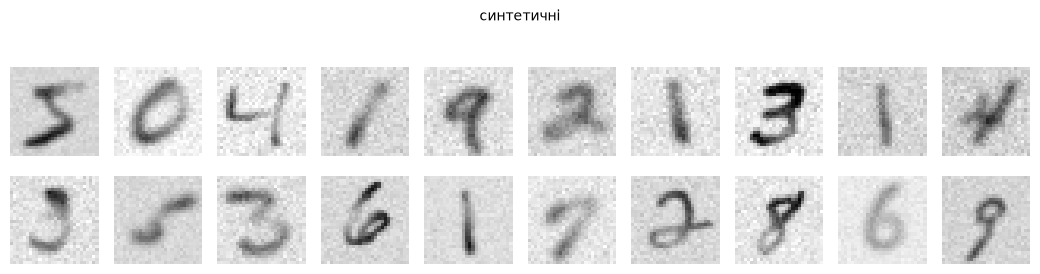

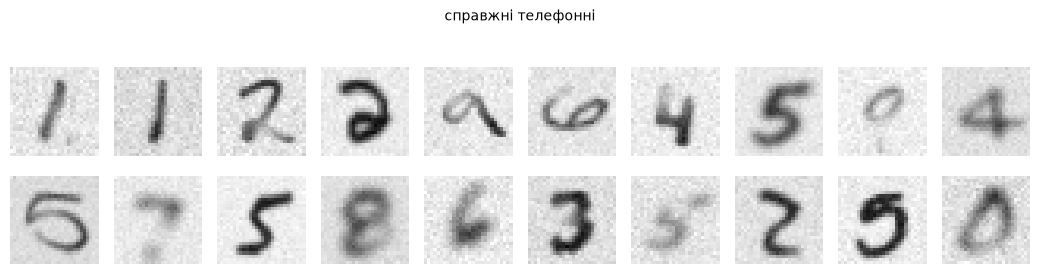

класифікатор відрізняє синтетичні фото від справжніх із точністю 61.5 %


,ліки,вал
0,база: модель B,9.00
1,+1000 випадкових фото з пулу,8.53
2,+1000 відібраних фото з пулу,8.00
3,+20 000 синтетичних фото,5.67


In [45]:
assert SYN, 'задайте параметри синтезу'
SYN_X = distort(SCAN_X, seed=42, share=SYN_SHARE, **SYN)
show_grid(SYN_X[:20], title='синтетичні'); show_grid(PHONE_X[:20], title='справжні телефонні')
Xd = np.concatenate([flat(PHONE_X[:1500]), flat(SYN_X[:1500])]); yd = np.r_[np.zeros(1500), np.ones(1500)]
SYN_DISCR = round(100 * float(cross_val_score(LogisticRegression(max_iter=500), Xd, yd, cv=5).mean()), 1)
print('класифікатор відрізняє синтетичні фото від справжніх із точністю', SYN_DISCR, '%')
m_syn, e = train_with(SYN_X, SCAN_Y)
FIX.append({'ліки': '+20 000 синтетичних фото', 'вал': e}); pd.DataFrame(FIX)

### Завдання 8.3. Остаточна модель і план

Зберіть остаточну модель з того, що спрацювало (одна тисяча куплених фото + синтез за
бажанням), і **один раз** оцініть її на тестовій вибірці.

In [46]:
# ----- ВАШІ ВІДПОВІДІ -----
FINAL_PURCHASE = 'відібрані'    # 'випадкові' / 'відібрані' / '' (без покупки)
FINAL_SYNTH = True              # True / False — чи додавати синтез
# ----- КІНЕЦЬ -----

In [47]:
assert FINAL_PURCHASE in ('випадкові', 'відібрані', '') and FINAL_SYNTH in (True, False)
parts_X, parts_y = [], []
if FINAL_PURCHASE:
    ids = rand_idx if FINAL_PURCHASE == 'випадкові' else SELECT
    parts_X.append(POOL_X[ids]); parts_y.append(POOL_Y[ids])
if FINAL_SYNTH:
    parts_X.append(SYN_X); parts_y.append(SCAN_Y)
FINAL, e = train_with(np.concatenate(parts_X), np.concatenate(parts_y)) if parts_X else (B, E_B['вал'])
FIX.append({'ліки': f'остаточна: покупка «{FINAL_PURCHASE or "—"}», синтез {"так" if FINAL_SYNTH else "ні"}', 'вал': e})
E_FINAL_TEST = evaluate_on_test(FINAL, 'остаточна модель')
print('остаточна модель: валідаційна', e, '%, тестова', E_FINAL_TEST, '%')
pd.DataFrame(FIX)

остаточна модель: валідаційна 5.6 %, тестова 4.33 %


,ліки,вал
0,база: модель B,9.00
1,+1000 випадкових фото з пулу,8.53
2,+1000 відібраних фото з пулу,8.00
3,+20 000 синтетичних фото,5.67
4,"остаточна: покупка «відібрані», синтез так",5.60


In [48]:
# ----- ВАШІ ВІДПОВІДІ -----
# план дій для команди: 3–5 кроків у порядку виконання, кожен — з очікуваним ефектом у п. п.
# і з посиланням на число з цього ноутбука; останній крок — що робити далі, коли бюджет вичерпано
PLAN = [
    'Крок 1. Синтез 20 000 «телефонних» фото зі сканів (blur 0.5-1.5, glare 0.2-1.0, фон 0.06-0.18, контраст 0.7-1.0, '
    'шум 0.02-0.05) і навчання моделі B на суміші + синтезі. Ефект: валідаційна похибка 9.00 -> 5.67 % (-3.33 п. п.); '
    'бюджету не потребує, тому робимо першим. Синтетику класифікатор відрізняє від справжніх фото лише з точністю 61.5 %.',
    'Крок 2. Докупити 1000 фото з пулу, відібраних без міток за малою різкістю і малою впевненістю моделі B. '
    'Окремо це дає 9.00 -> 8.00 % (-1.00 п. п.) проти 8.53 % для 1000 випадкових; разом із синтезом - 5.60 % '
    '(ще -0.07 п. п.). Остаточна модель: валідаційна 5.60 %, тестова 4.33 % (тест використано один раз).',
    'Крок 3. Повторити аналіз 100 помилок уже для остаточної моделі. Стеля розмиття + відблиску була 6.21 п. п., '
    'а використано 3.40 п. п. (9.00 -> 5.60), тож якщо ці вади ще домінують - покращувати синтез (наближати точність '
    'розрізнення синтетики до 50 %, підбирати діапазони blur і glare). Очікуваний ефект - до ~2.8 п. п.',
    'Крок 4. Розібратися з дисперсією: у моделі B вона 3.3 п. п. (навчальна 0.0 %, навчально-валідаційна 3.3 %). '
    'Спробувати регуляризацію (alpha у MLP) і аугментацію зсувами; це ж допоможе з категорією «інше» '
    '(31 помилка, стеля 2.79 п. п. - незвичний почерк). Очікуваний ефект - 1-2 п. п.',
    'Крок 5 (бюджет вичерпано). Безкоштовно збирати нові телефонні фото з робочого потоку: зберігати фото клієнтів, '
    'на яких модель невпевнена, і розмічати їх власними силами; уточнити людський рівень на більшій вибірці '
    '(4.0 % на 50 фото - груба оцінка: одна помилка = 2 %). Без точнішого людського рівня не можна сказати, '
    'скільки похибки ще можна усунути.',
]
# ----- КІНЕЦЬ -----

In [49]:
assert len(PLAN) >= 3, 'план має містити щонайменше три кроки'
for k, s in enumerate(PLAN, 1):
    print(k, s)

1 Крок 1. Синтез 20 000 «телефонних» фото зі сканів (blur 0.5-1.5, glare 0.2-1.0, фон 0.06-0.18, контраст 0.7-1.0, шум 0.02-0.05) і навчання моделі B на суміші + синтезі. Ефект: валідаційна похибка 9.00 -> 5.67 % (-3.33 п. п.); бюджету не потребує, тому робимо першим. Синтетику класифікатор відрізняє від справжніх фото лише з точністю 61.5 %.
2 Крок 2. Докупити 1000 фото з пулу, відібраних без міток за малою різкістю і малою впевненістю моделі B. Окремо це дає 9.00 -> 8.00 % (-1.00 п. п.) проти 8.53 % для 1000 випадкових; разом із синтезом - 5.60 % (ще -0.07 п. п.). Остаточна модель: валідаційна 5.60 %, тестова 4.33 % (тест використано один раз).
3 Крок 3. Повторити аналіз 100 помилок уже для остаточної моделі. Стеля розмиття + відблиску була 6.21 п. п., а використано 3.40 п. п. (9.00 -> 5.60), тож якщо ці вади ще домінують - покращувати синтез (наближати точність розрізнення синтетики до 50 %, підбирати діапазони blur і glare). Очікуваний ефект - до ~2.8 п. п.
4 Крок 4. Розібратися з 

## 9. Аналіз помилок за частинами

Сервіс отримує не вирізану цифру, а фото бланка 56 × 56: цифра може бути будь-де, поруч — плями
(лекція 10, розділи 53–54). Конвеєр:

* **A** — локалізатор без навчання (`locate`): знаходить цифру і вирізає 28 × 28;
* **Cʹ** — класифікатор, навчений на суміші і на копіях, зсунутих на 1–2 пікселі.

Тест книжки: підставте замість виходу A **ідеальний** виріз (справжнє положення цифри). Якщо
відповідь стала правильною — помилка на совісті A, якщо ні — Cʹ.

Cʹ навчено за 24 с


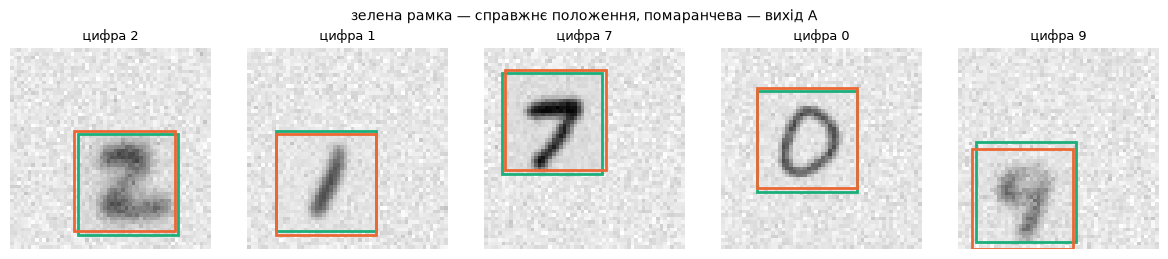

In [50]:
CANVAS = INFO['полотна']
CX, CPOS = make_canvas(DEV_X, 500 + VARIANT, blobs=tuple(CANVAS['плями']), lines=CANVAS['лінії'])
t0 = time.time()
Cp = model_b().fit(np.concatenate([XB_tr, flat(shifted_copies(MIX_X[mix_tr][::2], 5))]), np.concatenate([yB_tr, yB_tr[::2]]))
POS_A = locate(CX)
print(f'Cʹ навчено за {time.time() - t0:.0f} с')
fig, axs = plt.subplots(1, 5, figsize=(12, 2.6))
for k, ax in enumerate(axs):
    ax.imshow(CX[k], cmap='gray_r', vmin=0, vmax=1)
    for (r0, c0), col in [(CPOS[k], C3), (POS_A[k], C2)]:
        ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), 28, 28, fill=False, color=col, lw=2))
    ax.set_title(f'цифра {DEV_Y[k]}', fontsize=9); ax.axis('off')
fig.suptitle('зелена рамка — справжнє положення, помаранчева — вихід A', fontsize=10); plt.tight_layout(); plt.show()

### Завдання 9.1

Допишіть три рядки: прогноз системи на вирізах A, прогноз Cʹ на ідеальних вирізах і маску помилок.
Функції: `crop(CX, POS_A)`, `crop(CX, CPOS)`, `flat(...)`, `Cp.predict(...)`.

In [55]:
# ----- ВАШІ ВІДПОВІДІ -----
pred_sys = Cp.predict(flat(crop(CX, POS_A)))     # прогноз системи A → Cʹ
pred_ideal = Cp.predict(flat(crop(CX, CPOS)))    # прогноз Cʹ на ідеальних вирізах
wrong_sys = pred_sys != DEV_Y                    # True там, де система помилилась
# ----- КІНЕЦЬ -----

In [56]:
blame_A = int((wrong_sys & (pred_ideal == DEV_Y)).sum()); blame_C = int((wrong_sys & (pred_ideal != DEV_Y)).sum())
PARTS = {'похибка_системи': round(100 * float(wrong_sys.mean()), 2), 'помилок': int(wrong_sys.sum()), 'вина_A': blame_A, 'вина_C': blame_C,
         'A_влучив': round(100 * float((np.abs(POS_A - CPOS) <= 2).all(1).mean()), 1)}
PARTS

{'похибка_системи': 28.8,
 'помилок': 432,
 'вина_A': 291,
 'вина_C': 141,
 'A_влучив': 70.4}

In [57]:
# ----- ВАШІ ВІДПОВІДІ -----
PARTS_VERDICT = 'A'     # 'A' або 'C' — який компонент покращувати першим
PARTS_WHY = ('Похибка системи A -> Cʹ - 28.8 % (432 помилки з 1500). Тест з ідеальним вирізом: у 291 випадку (67 %) '
             'Cʹ на ідеальному вирізі відповідає правильно, тобто винен локалізатор A; лише у 141 випадку (33 %) Cʹ '
             'помиляється і на ідеальному вирізі. A влучає (похибка положення не більше 2 пікселів) лише на 70.4 % бланків. '
             'З ідеальним A похибка впала б до 141 / 1500 = 9.4 % (стеля покращення A - 19.4 п. п.), що близько до похибки '
             'моделі B на вирізаних фото (9.0 %). Тому першим покращую A: рахувати поріг чорнила відносно фону кожного '
             'бланка замість фіксованого thr = 0.3 (на моїх фото цифри розмиті й засвічені, тож бліді штрихи губляться), '
             'і відкидати плями за формою та розміром компоненти, а не лише за сумою чорнила. Як дешевий додатковий крок - '
             'навчати Cʹ на більших зсувах (±3-4 пікселі), щоб він витримував неточні вирізи.')
# ----- КІНЕЦЬ -----

In [58]:
assert PARTS_VERDICT in ('A', 'C') and PARTS_WHY

## 10. Звіт колеги на критику

Колега з іншої команди розв'язував ту саму задачу на своїх даних (варіанта з такими числами
в групі немає) і надіслав звіт. У ньому **сім** методичних помилок. Знайдіть щонайменше
**п'ять**: для кожної — номер пункту, у чому помилка і як треба було зробити (з посиланням
на розділ книжки).

> **Звіт: модель читання цифр із фото, версія 2**
>
> **1. Поділ даних.** Перемішав усі 26 000 зображень (20 000 сканів і 6000 фото) і випадково
> відклав по 10 % на валідаційну і тестову вибірки.
>
> **2. Людський рівень.** Я і троє колег підписали по 50 фото; середня похибка — 6 %, найкраща — 1 %.
> Модель на валідаційній вибірці помиляється у 2,4 % випадків, тобто вже краща за людей:
> усувного відхилення немає, працювати над моделлю далі немає сенсу.
>
> **3. Діагноз.** На фото, які надсилають клієнти, похибка — 11,8 %; на навчально-валідаційній
> вибірці — 2,9 %, на навчальній — 0,3 %. Це перенавчання (висока дисперсія). Посилив
> регуляризацію (alpha = 1): навчальна 2,1 %, фото клієнтів — 12,6 %. Дивно, що не допомогло.
>
> **4. Аналіз помилок.** Переглянув 100 помилок на фото клієнтів: 40 із них розмиті. Якщо
> усунути розмиття, похибка зменшиться на 40 % — до 0,4 %. Тому розмиття — пріоритет номер один.
>
> **5. Синтез.** Сфотографував чистий аркуш у кафе і наклав цей самий фон на всі 20 000 сканів.
> На валідаційній вибірці з пункту 1 похибка впала з 2,4 % до 2,1 % — синтез працює.
>
> **6. Вибір моделі.** Порівняв 12 варіантів моделі на тестовій вибірці й обрав найкращий —
> 9,7 %. Це і є очікувана похибка в клієнтів.
>
> **7. Аналіз за частинами.** Підставив замість відповіді класифікатора правильну цифру — і система
> стала правильною в 100 % випадків. Отже, усі помилки — від класифікатора, локалізатор не винен.

In [64]:
# ----- ВАШІ ВІДПОВІДІ -----
CRITIQUE = [
    {'пункт': 1,
     'помилка': 'Змішав скани і фото й відклав з цієї суміші валідаційну і тестову вибірки: вони складаються переважно зі сканів і не відображають фото клієнтів.',
     'як_правильно': 'Валідаційну і тестову брати лише з телефонних фото - розподілу, на якому працюватиме сервіс; скани - лише в навчальну.'},
    {'пункт': 2,
     'помилка': 'Як людський рівень узяв середнє 6 % замість найкращого 1 % і порівняв його з валідаційною похибкою на суміші; висновок «працювати далі немає сенсу» хибний.',
     'як_правильно': 'Людський рівень - найкращий результат (1 %); усувне відхилення = навчальна похибка - 1 %, і дивитись на всі три складові.'},
    {'пункт': 3,
     'помилка': 'Розрив 11.8 - 2.9 = 8.9 п. п. між фото клієнтів і навчально-валідаційною - це розбіжність даних, а не дисперсія (вона лише 2.9 - 0.3 = 2.6 п. п.); тому регуляризація не допомогла.',
     'як_правильно': 'Розкласти похибку на відхилення, дисперсію і розбіжність і лікувати найбільшу складову - розбіжність (даними, схожими на фото).'},
    {'пункт': 4,
     'помилка': 'Якщо 40 % помилок розмиті, похибка зменшиться не на 40 % до 0.4 %, а максимум на 40 % від 11.8 %, тобто на 4.72 п. п. - до ~7.1 %.',
     'як_правильно': 'Стеля = похибка * частка помилок категорії.'},
    {'пункт': 5,
     'помилка': 'Один і той самий фон на всіх 20 000 сканах - пастка «однієї години шуму»: модель запам\'ятає цей фон. Перевірка на валідаційній з пункту 1 (переважно скани) нічого не каже про фото.',
     'як_правильно': 'Синтезувати з багатьма різними фонами і параметрами-діапазонами, перевіряти схожість на справжні фото і ефект на валідаційній з телефонних фото.'},
    {'пункт': 6,
     'помилка': 'Обирав модель серед 12 варіантів за тестовою вибіркою - тест підігнано, і 9.7 % - занижена (оптимістична) оцінка.',
     'як_правильно': 'Обирати модель за валідаційною вибіркою, а тестову використати один раз - для остаточної оцінки обраної моделі.'},
    {'пункт': 7,
     'помилка': 'Підставив правильну відповідь замість останнього компонента (класифікатора) - система тривіально стала правильною на 100 %, це нічого не перевіряє.',
     'як_правильно': 'Підставляти ідеальний вихід попереднього компонента (правильний виріз від локалізатора) і дивитись, чи класифікатор усе одно помиляється.'},
]
# ----- КІНЕЦЬ -----

In [65]:
assert len(CRITIQUE) >= 5 and all(c.get('помилка') and c.get('як_правильно') for c in CRITIQUE), 'потрібно щонайменше 5 знайдених помилок'
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(CRITIQUE).style.set_properties(**{'text-align': 'left'}))

,пункт,помилка,як_правильно
0,1,Змішав скани і фото й відклав з цієї суміші валідаційну і тестову вибірки: вони складаються переважно зі сканів і не відображають фото клієнтів.,"Валідаційну і тестову брати лише з телефонних фото - розподілу, на якому працюватиме сервіс; скани - лише в навчальну."
1,2,Як людський рівень узяв середнє 6 % замість найкращого 1 % і порівняв його з валідаційною похибкою на суміші; висновок «працювати далі немає сенсу» хибний.,"Людський рівень - найкращий результат (1 %); усувне відхилення = навчальна похибка - 1 %, і дивитись на всі три складові."
2,3,"Розрив 11.8 - 2.9 = 8.9 п. п. між фото клієнтів і навчально-валідаційною - це розбіжність даних, а не дисперсія (вона лише 2.9 - 0.3 = 2.6 п. п.); тому регуляризація не допомогла.","Розкласти похибку на відхилення, дисперсію і розбіжність і лікувати найбільшу складову - розбіжність (даними, схожими на фото)."
3,4,"Якщо 40 % помилок розмиті, похибка зменшиться не на 40 % до 0.4 %, а максимум на 40 % від 11.8 %, тобто на 4.72 п. п. - до ~7.1 %.",Стеля = похибка * частка помилок категорії.
4,5,Один і той самий фон на всіх 20 000 сканах - пастка «однієї години шуму»: модель запам'ятає цей фон. Перевірка на валідаційній з пункту 1 (переважно скани) нічого не каже про фото.,"Синтезувати з багатьма різними фонами і параметрами-діапазонами, перевіряти схожість на справжні фото і ефект на валідаційній з телефонних фото."
5,6,"Обирав модель серед 12 варіантів за тестовою вибіркою - тест підігнано, і 9.7 % - занижена (оптимістична) оцінка.","Обирати модель за валідаційною вибіркою, а тестову використати один раз - для остаточної оцінки обраної моделі."
6,7,"Підставив правильну відповідь замість останнього компонента (класифікатора) - система тривіально стала правильною на 100 %, це нічого не перевіряє.","Підставляти ідеальний вихід попереднього компонента (правильний виріз від локалізатора) і дивитись, чи класифікатор усе одно помиляється."


---
# Частина 3. Звіт (0,5 бала)
---
## 11. Звіт

Відповідайте **числами з цього ноутбука**, а не загальними словами.

1. **Діагноз виробничої моделі.** Назвіть три похибки і три складові розкладу. Чому
   навчально-валідаційну вибірку взято саме з того джерела?
2. **Людський рівень.** Ваша похибка на 50 фото і найкраща в групі для вашого варіанта.
   Чи змінив би діагноз людський рівень 0 %? А 5 %?
3. **Крива навчання.** Чи допоможуть дані того самого джерела? Що на графіку це показує?
4. **Дії.** Які дві дії допомогли, на скільки п. п.? Що сталося з контрольною дією і чому?
5. **Модель B.** Яка складова її похибки головна і чому більше сканів її не зменшить?
6. **Аналіз помилок.** Три пріоритети зі стелями. Яка частка похибки — хибні мітки?
   Чи варто виправляти мітки валідаційної вибірки?
7. **Ліки.** Що дало найбільший виграш і чи вклався він у стелю з пункту 6? Наскільки
   синтетичні фото відрізняються від справжніх?
8. **Тест.** Валідаційна і тестова похибки остаточної моделі. Скільки разів ви зверталися до
   тестової вибірки?
9. **Аналіз за частинами.** Хто винен частіше — A чи Cʹ — і що ви зробите першим?
10. **Звіт колеги.** Яка з його помилок найдорожча для замовника і чому?

In [62]:
# ----- ВАШІ ВІДПОВІДІ -----
REPORT = '''
1. Похибки виробничої моделі (PCA(10) + LogReg на суміші): навчальна 21.02 %, навчально-валідаційна 22.35 %,
   валідаційна 31.67 %. Розклад: усувне відхилення 17.02 п. п., дисперсія 1.33 п. п., розбіжність 9.32 п. п.
   Діагноз - відхилення. Навчально-валідаційну вибірку взято з суміші, бо на ній навчалась модель: тоді
   різниця з навчальною показує лише дисперсію, а не змішує її з розбіжністю даних.

2. Моя похибка на 50 фото - 4.0 % (2 помилки: фото 22 і 32); кращого результату для варіанта 17 у групі немає,
   тому людський рівень - 4.0 %. При 0 % усувне відхилення було б 21.02 п. п., при 5 % - 16.02 п. п.;
   в обох випадках воно найбільше, тож діагноз не змінився б.

3. Ні. Обидві криві майже пласкі: при збільшенні даних з 2000 до 20000 навчально-валідаційна похибка впала
   лише з 23.30 % до 22.35 %; розрив між кривими ~1.3 п. п., обидві на плато ~21-22 % - далеко над людським
   рівнем 4 %. Це ознака відхилення: модель занадто проста.

4. PCA(100) + LogReg: валідаційна 31.67 -> 16.13 % (-15.54 п. п.). MLP(256): 31.67 -> 9.00 % (-22.67 п. п.),
   навчальна 0.00 %. Контрольна дія (C = 0.01, проти дисперсії) не допомогла: дисперсія -0.03 п. п.,
   відхилення +0.43 п. п., валідаційна 30.27 %, бо дисперсії майже не було, а регуляризація ще обмежила модель.

5. Модель B: навчальна 0.0 %, навчально-валідаційна 3.3 %, валідаційна 9.0 %. Відхилення -4.0 п. п. (усунуто),
   дисперсія 3.3 п. п., розбіжність 5.7 п. п. - головна складова. Більше сканів її не зменшить: вони з того
   самого розподілу і не навчать модель читати розмиті й засвічені фото.

6. Пріоритети: розмиття (44 помилки, стеля 3.96 п. п.), відблиск (33, стеля 2.97 п. п.); спільна стеля
   6.21 п. п. «Інше» (31, 2.79 п. п.) - незвичний почерк, цілеспрямованих ліків немає. Хибних міток 0 %
   (9.0 % -> 9.0 %), тому виправляти мітки валідаційної вибірки не потрібно.

7. Найбільший виграш дав синтез 20 000 фото: 9.00 -> 5.67 % (-3.33 п. п.); відібрана покупка дала -1.00 п. п.
   (8.00 %), випадкова -0.47 п. п. (8.53 %). Разом 9.00 -> 5.60 % (-3.40 п. п.) - вклалось у стелю 6.21 п. п.
   Класифікатор відрізняє синтетичні фото від справжніх із точністю 61.5 % (50 % - не відрізняє).

8. Остаточна модель (відібрані + синтез): валідаційна 5.60 %, тестова 4.33 %. Тестову вибірку використано один раз.

9. Похибка системи 28.8 % (432 помилки): вина A - 291, вина Cʹ - 141; A влучає лише на 70.4 % бланків.
   Першим покращую A: поріг чорнила відносно фону бланка і відкидання плям за формою. З ідеальним A похибка
   впала б до 9.4 %.

10. Найдорожча помилка - пункт 1: валідаційна і тестова вибірки зі суміші, переважно зі сканів. Через це всі
    його числа (2.4 %, 9.7 %) не показують якість на фото клієнтів (там 11.8 %), і замовник отримає модель,
    гіршу, ніж обіцяно; на цих вибірках неправильні й усі подальші висновки.

Декларація про використання ШІ: використовував ШІ-асистента (Claude) для пояснення теорії, підказок до коду,
чернетки розмітки 100 помилок і формулювань відповідей. Усі числа отримав, запускаючи ноутбук; розмітку
помилок, людський рівень і висновки перевіряв самостійно.
'''
# ----- КІНЕЦЬ -----

### Декларація про використання штучного інтелекту

Наприкінці звіту зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; не дозволено видавати чуже за своє.

In [63]:
def _num(d):
    return {k: (round(float(v), 4) if isinstance(v, (int, float, np.floating, np.integer)) else v) for k, v in d.items()}


result = {
    'студент': STUDENT_NAME, 'номер': LIST_NUMBER, 'варіант': VARIANT,
    'версія_sklearn': sklearn.__version__,
    'джерело_навч_вал': TRAIN_SOURCE, 'чому_навч_вал': WHY_TRAIN_DEV,
    'людина': {'відповіді': HUMAN_ANSWERS, 'похибка': HUMAN_ERR},
    'виробнича': {'похибки': _num(E_PROD), 'розклад': _num(DECOMP_PROD), 'діагноз': DIAGNOSIS, 'доказ': DIAGNOSIS_WHY},
    'крива': CURVE.to_dict('records'), 'більше_тих_самих_даних': MORE_SAME_DATA_HELPS, 'крива_чому': CURVE_WHY,
    'дії': ACT_TABLE.round(2).to_dict('records'), 'дії_висновок': ACTIONS_CONCLUSION,
    'B': {'похибки': _num(E_B), 'розклад': _num(DECOMP_B), 'діагноз': DIAGNOSIS_B, 'чому': DIAGNOSIS_B_WHY,
          'за_виправленими_мітками': E_B_FIXED, 'виправлено_міток': len(relabel)},
    'аналіз_помилок': {'мітки': TAGS, 'номери_фото': ERR_IDX.tolist(), 'таблиця': ERR_TABLE.to_dict('records'),
                       'пріоритет': PRIORITY, 'чому': PRIORITY_WHY},
    'ліки': FIX, 'відбір': {'номери': SELECT.tolist(), 'чому': SELECT_WHY},
    'синтез': {'параметри': {k: list(v) for k, v in SYN.items()}, 'частка': SYN_SHARE, 'розрізнення_%': SYN_DISCR},
    'остаточна': {'покупка': FINAL_PURCHASE, 'синтез': FINAL_SYNTH, 'тест': E_FINAL_TEST, 'звернень_до_тесту': len(_TEST_CALLS)},
    'план': PLAN,
    'частини': PARTS, 'частини_висновок': PARTS_VERDICT, 'частини_чому': PARTS_WHY,
    'критика': CRITIQUE, 'звіт': REPORT,
}
fname = 'lr7_результат_%02d.json' % LIST_NUMBER
with open(fname, 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print('збережено', fname)

збережено lr7_результат_17.json


---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок (повний прогін — 10–15 хвилин).
* Усі `assert` зелені.
* Файл `lr7_результат_NN.json` створено; здайте його разом із ноутбуком.
* Тестову вибірку використано **один** раз.
* У звіті — числа, а не загальні формулювання; декларацію про ШІ заповнено.